In [1]:
#환경 확인
import torch, torchvision
from torch.utils.data import DataLoader

device = "cuda" if torch.cuda.is_available() else "cpu"
print(torch.__version__)
print(device)

2.13.0+cu126
cuda


In [2]:
total, batch = 60000, 64

print(total // batch)
print(total % batch)
print(937 + 1)

937
32
938


In [35]:
import torch
from torchvision import datasets, transforms

train_all = datasets.MNIST(root = "data", train = True, download = True, transform = transforms.ToTensor())

print(len(train_all))
x0, y0 = train_all[0]
print(type(x0).__name__, y0)
print(x0.shape)
print(x0.min().item(), x0.max().item())

60000
Tensor 5
torch.Size([1, 28, 28])
0.0 1.0


In [36]:
import torch
from torchvision import datasets, transforms

test = datasets.MNIST(root = "data", train = False, download = True, transform = transforms.ToTensor())
print(len(test))

x100, y100 = test[100]
print(x100.shape, y100)
print((test.targets[:1000] == 7).sum())

10000
torch.Size([1, 28, 28]) 6
tensor(99)


In [49]:
import torch
from torchvision import datasets, transforms

train_all = datasets.MNIST(root = "data", train = True, download = True, transform = transforms.ToTensor())

from torch.utils.data import DataLoader

loader = DataLoader(train_all, batch_size = 64, shuffle = True)
print(len(loader))

x, y = next(iter(loader)) # 첫 배치 하나 꺼내보기
print(x.shape)
print(y.shape)
print(y[:8].tolist())

938
torch.Size([64, 1, 28, 28])
torch.Size([64])
[8, 8, 5, 4, 4, 7, 0, 7]


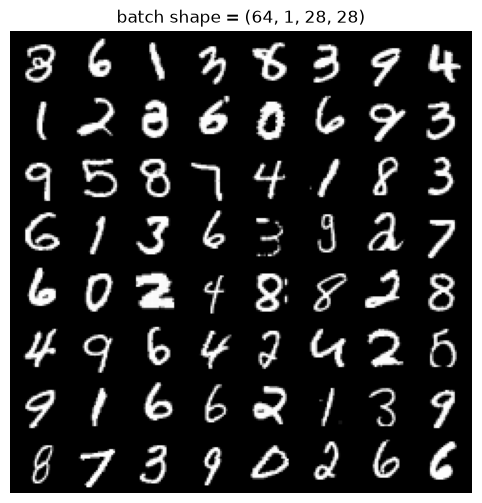

[3, 6, 1, 3, 8, 3, 9, 4]


In [50]:
import matplotlib.pyplot as plt
from torchvision.utils import make_grid

x, y = next(iter(loader))
grid = make_grid(x, nrow = 8)
plt.figure(figsize = (6, 6))
plt.imshow(grid.permute(1, 2, 0))
plt.title(f"batch shape = {tuple(x.shape)}"); plt.axis("off"); plt.show()
print(y[:8].tolist())

In [51]:
import torch
from torchvision import datasets, transforms
train_all = datasets.MNIST(root="data", train=True, download=True,
 transform=transforms.ToTensor())
from torch.utils.data import DataLoader
plain = DataLoader(train_all, batch_size=8, shuffle=False)
mixed = DataLoader(train_all, batch_size=8, shuffle=True)

print(next(iter(plain))[1].tolist())
print(next(iter(mixed))[1].tolist())

[5, 0, 4, 1, 9, 2, 1, 3]
[8, 2, 1, 3, 3, 1, 1, 4]


In [61]:
#2-4

import torch
from torchvision import datasets, transforms

train_all = datasets.MNIST(root = 'data', train = True, download = True, transform = transforms.ToTensor())

from torch.utils.data import DataLoader, random_split

g = torch.Generator().manual_seed(0)
train_set, val_set = random_split(train_all, [50000, 10000], generator = g)
print(len(train_set), len(val_set))

train_loader = DataLoader(train_set, batch_size = 8192, shuffle = True)
val_loader = DataLoader(val_set, batch_size = 819, shuffle = False)
print(len(train_loader), len(val_loader))

50000 10000
7 13


In [62]:
#2-5
import torch.nn as nn

device = "cuda" if torch.cuda.is_available() else "cpu"
torch.manual_seed(0) # 재현용
model = nn.Sequential(nn.Linear(784, 100), nn.ReLU(), nn.Linear(100, 10)).to(device) # 지난주 모델 그대로
opt = torch.optim.SGD(model.parameters(), lr=0.1)
loss_fn = nn.CrossEntropyLoss()

for epoch in range(3): # 3 epoch
    for x, y in train_loader: # 배치 782개 순회
        x, y = x.view(-1, 784).to(device), y.to(device) # 배치를 펴서 GPU로
        loss = loss_fn(model(x), y) # 지난주와 같은 학습 단계
        opt.zero_grad(); loss.backward(); opt.step()
        correct = 0 # epoch 끝마다 검증
    with torch.no_grad():
        for x, y in val_loader:
            x, y = x.view(-1, 784).to(device), y.to(device)
            correct += (model(x).argmax(dim=1) == y).sum().item()
    print(epoch + 1, round(correct / 10000 * 100, 1))

1 41.6
2 60.5
3 68.8


In [63]:
#2-5
import torch.nn as nn

device = "cuda" if torch.cuda.is_available() else "cpu"
torch.manual_seed(0) # 재현용
model = nn.Sequential(nn.Linear(784, 100), nn.ReLU(), nn.Linear(100, 10)).to(device) # 지난주 모델 그대로
opt = torch.optim.SGD(model.parameters(), lr=0.1)
loss_fn = nn.CrossEntropyLoss()

for epoch in range(6): # 3 epoch
    for x, y in train_loader: # 배치 782개 순회
        x, y = x.view(-1, 784).to(device), y.to(device) # 배치를 펴서 GPU로
        loss = loss_fn(model(x), y) # 지난주와 같은 학습 단계
        opt.zero_grad(); loss.backward(); opt.step()
        correct = 0 # epoch 끝마다 검증
    with torch.no_grad():
        for x, y in val_loader:
            x, y = x.view(-1, 784).to(device), y.to(device)
            correct += (model(x).argmax(dim=1) == y).sum().item()
    print(epoch + 1, round(correct / 10000 * 100, 1))

1 41.6
2 60.5
3 68.8
4 71.5
5 73.6
6 75.2
